In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from tqdm import tqdm
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

In [6]:
df = pd.read_csv("insurance (12).csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
X,y = df.drop("charges",axis=1), df["charges"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3)

In [8]:
ohc = OneHotEncoder(sparse_output=False, drop="first").set_output(transform="pandas")
ct = make_column_transformer((ohc,make_column_selector(dtype_include=object)),
                             ("passthrough", make_column_selector(dtype_include=['int64','float64'])),
                             verbose_feature_names_out=False)
ct = ct.set_output(transform='pandas')

## GradientBoostingRegressor

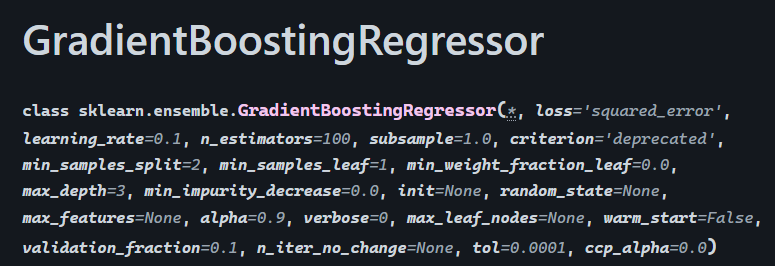

In [14]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdr = GradientBoostingRegressor(random_state=26,learning_rate=l, n_estimators= n, max_depth= m)
            pipe = Pipeline([("CT",ct),("GDC",gdr)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:15<00:00,  1.53s/it]


,Learning Rate,Max Depth,N,Score
19,0.108889,3.0,50,0.869232
30,0.207778,3.0,25,0.869119
20,0.108889,3.0,100,0.868956
18,0.108889,3.0,25,0.866720
42,0.306667,3.0,25,0.866690
...,...,...,...,...
4,0.010000,2.0,50,0.522892
9,0.010000,4.0,25,0.344310
0,0.010000,NaN,25,0.339508
6,0.010000,3.0,25,0.338345


## XGBRegressor

In [19]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdm = XGBRegressor(random_state=26,learning_rate=l, n_estimators= n, max_depth= m)
            pipe = Pipeline([("CT",ct),("GDM",gdm)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:17<00:00,  1.73s/it]


,Learning Rate,Max Depth,N,Score
19,0.108889,3.0,50,0.872067
30,0.207778,3.0,25,0.871976
39,0.306667,2.0,25,0.871520
22,0.108889,4.0,50,0.870778
33,0.207778,4.0,25,0.870762
...,...,...,...,...
4,0.010000,2.0,50,0.522753
0,0.010000,NaN,25,0.339735
9,0.010000,4.0,25,0.338969
6,0.010000,3.0,25,0.335574


## LGBMRegressor

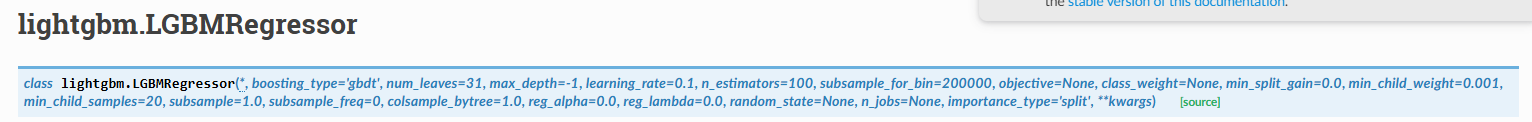

In [20]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

In [21]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdm = LGBMRegressor(random_state=26,verbose = -1,learning_rate=l, n_estimators= n, max_depth= m)
            pipe = Pipeline([("CT",ct),("GDM",gdm)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:04<00:00,  2.23it/s]


,Learning Rate,Max Depth,N,Score
30,0.207778,3.0,25,0.870819
31,0.207778,3.0,50,0.869950
19,0.108889,3.0,50,0.869713
17,0.108889,2.0,100,0.869398
22,0.108889,4.0,50,0.869261
...,...,...,...,...
4,0.010000,2.0,50,0.522892
0,0.010000,NaN,25,0.347231
9,0.010000,4.0,25,0.344334
6,0.010000,3.0,25,0.338345


## CatBoostRegressor

In [25]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdm = CatBoostRegressor(random_state=26,verbose = False,learning_rate=l, n_estimators= n, max_depth= m)
            pipe = Pipeline([("CT",ct),("GDC",gdm)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:24<00:00,  2.50s/it]


,Learning Rate,Max Depth,N,Score
31,0.207778,3.0,50,0.874315
99,0.801111,2.0,25,0.873775
78,0.603333,3.0,25,0.873340
34,0.207778,4.0,50,0.873296
32,0.207778,3.0,100,0.872602
...,...,...,...,...
4,0.010000,2.0,50,0.460703
9,0.010000,4.0,25,0.303635
6,0.010000,3.0,25,0.302483
0,0.010000,NaN,25,0.290878


In [27]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

## CatBoostRegressor using cat_features

In [29]:
lr = np.linspace(0.01,0.9,10)
max_depth = [None, 2, 3, 4]
n_estimators = [25, 50, 100]
categorial_features = ["sex","smoker","region"]
scores = []
for l in tqdm(lr):
    for m in max_depth:
        for n in n_estimators:
            gdm = CatBoostRegressor(random_state=26,verbose = False,cat_features=categorial_features,learning_rate=l, n_estimators= n, max_depth= m)
            gdm.fit(X_train,y_train)
            y_pred = gdm.predict(X_test)
            scores.append([l,m,n,r2_score(y_test, y_pred)])
df_scores = pd.DataFrame(scores, columns=["Learning Rate","Max Depth", "N", "Score"])
df_scores.sort_values("Score",ascending=False)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [02:34<00:00, 15.41s/it]


,Learning Rate,Max Depth,N,Score
20,0.108889,3.0,100,0.873361
23,0.108889,4.0,100,0.871817
42,0.306667,3.0,25,0.871504
36,0.306667,NaN,25,0.871146
14,0.108889,NaN,100,0.871091
...,...,...,...,...
4,0.010000,2.0,50,0.465715
6,0.010000,3.0,25,0.300450
9,0.010000,4.0,25,0.296912
0,0.010000,NaN,25,0.293823
